# Aulas IA Preditiva Modulo1 Semana 08 Aula2

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# from script_functions import mostrar,barras_vertical,barras_horizontal,pizza,dispersao
import script_functions as fnc 


referencia = pd.Timestamp("2026-09-30")
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="pastel" # "Set2", "muted"
)

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 11,
    "axes.facecolor": "#F7FAFC", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 14,
    "axes.titlepad": 18, "grid.alpha": 0.28,
    "grid.color": "#A6BBC7", "axes.edgecolor": "#CBD5DD"
})

print("Referência:", referencia.date())
print("Dados fictícios para uso didático.")

Referência: 2026-09-30
Dados fictícios para uso didático.
Referência: 2026-09-30
Dados fictícios para uso didático.


In [2]:
df = pd.read_csv("dados_rh.csv", encoding="utf-8-sig")

df = df.rename(columns={
    "ID": "id", "nome de integrante": "nome",
    "salário": "salario", "faixa de idade": "faixa_idade",
    "data de contratação": "data_contratacao",
    "status do integrante": "status"
})
print("Dimensões:", df.shape)
#print(df.head(4).to_string(index=False))

df.head(5)

Dimensões: (2400, 10)


,id,nome,salario,cargo,idade,faixa_idade,sexo,data_contratacao,status,departamento
0,0,Anna Liz Sampaio,4163.00,Baterista,65,60-69,Masculino,2020-01-23,Ativo,administrativo
1,1,Noah Abreu,9886.00,Cientista da informação e documentação,63,60-69,Feminino,2022-11-29,Ativo,administrativo
2,2,Sra. Julia da Rosa,8026.00,Optometrista,58,50-59,Feminino,2020-02-11,Inativo,administrativo
3,3,Pietro Ramos,7797.00,Mensageiro,22,20-29,Feminino,2020-07-09,Inativo,administrativo
4,4,Bruno Ferreira Esteves,2526.17,Assistente comercial,45,40-49,Feminino,2023-06-15,Ativo,comercial


In [3]:
# Convertendo para datetime

df["data_contratacao"] = pd.to_datetime(df["data_contratacao"], format="%Y-%m-%d")
df["ano"] = df["data_contratacao"].dt.year
df["mes"] = df["data_contratacao"].dt.month
df["trimestre"] = df["data_contratacao"].dt.to_period("Q")
df["anos_desde_admissao"] = (
    (referencia - df["data_contratacao"]).dt.days / 365.2425
)

df.head(5)

,id,nome,salario,cargo,idade,faixa_idade,sexo,data_contratacao,status,departamento,ano,mes,trimestre,anos_desde_admissao
0,0,Anna Liz Sampaio,4163.00,Baterista,65,60-69,Masculino,2020-01-23,Ativo,administrativo,2020,1,2020Q1,6.685969
1,1,Noah Abreu,9886.00,Cientista da informação e documentação,63,60-69,Feminino,2022-11-29,Ativo,administrativo,2022,11,2022Q4,3.835808
2,2,Sra. Julia da Rosa,8026.00,Optometrista,58,50-59,Feminino,2020-02-11,Inativo,administrativo,2020,2,2020Q1,6.633949
3,3,Pietro Ramos,7797.00,Mensageiro,22,20-29,Feminino,2020-07-09,Inativo,administrativo,2020,7,2020Q3,6.226001
4,4,Bruno Ferreira Esteves,2526.17,Assistente comercial,45,40-49,Feminino,2023-06-15,Ativo,comercial,2023,6,2023Q2,3.293702


In [4]:
df_plano = pd.DataFrame({
    "departamento": ["administrativo", "comercial", "financeiro",
                     "operações", "recursos humanos", "tecnologia"],
    "quadro_planejado": [300, 410, 250, 540, 210, 400],
    "orcamento_mensal": [1600, 2500, 1650, 2400, 1300, 3700]
})

fnc.mostrar(df_plano)

    departamento  quadro_planejado  orcamento_mensal
  administrativo               300              1600
       comercial               410              2500
      financeiro               250              1650
       operações               540              2400
recursos humanos               210              1300
      tecnologia               400              3700


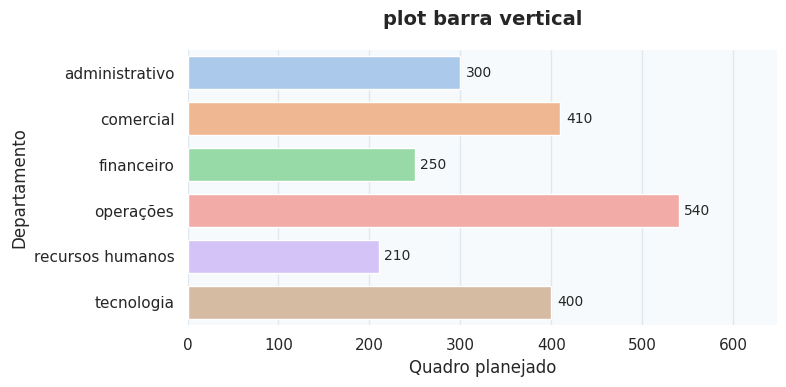

In [5]:
fnc.barras_horizontal(df_plano, "departamento", "quadro_planejado", titulo="plot barra vertical")

### Qual é o salário médio por departamento?


 ['administrativo', 'comercial', 'recursos humanos', 'tecnologia', 'operações', 'jurídico', 'financeiro']
 id                         nome  salario                                  cargo  idade faixa_idade      sexo data_contratacao status     departamento  ano  mes trimestre  anos_desde_admissao
  0             Anna Liz Sampaio  4163.00                              Baterista     65       60-69 Masculino       2020-01-23  Ativo   administrativo 2020    1    2020Q1                 6.69
  1                   Noah Abreu  9886.00 Cientista da informação e documentação     63       60-69  Feminino       2022-11-29  Ativo   administrativo 2022   11    2022Q4                 3.84
  4       Bruno Ferreira Esteves  2526.17                   Assistente comercial     45       40-49  Feminino       2023-06-15  Ativo        comercial 2023    6    2023Q2                 3.29
  5          Valéria Costa Gomes  4864.94                         Analista de RH     29       20-29 Masculino       2022-10-1

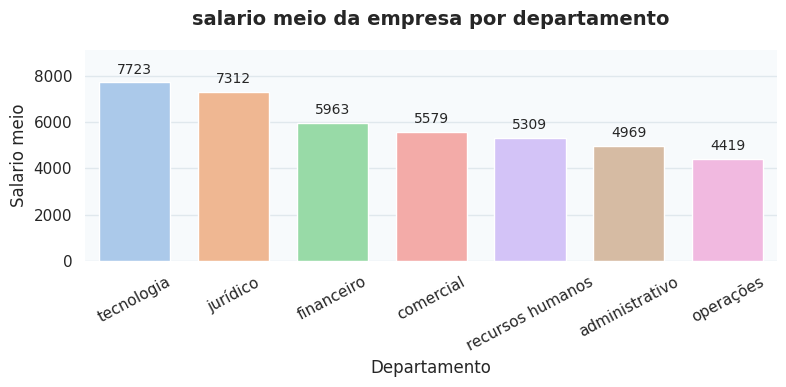

In [6]:
ativos = df.loc[df["status"] == "Ativo"].copy()
print("\n", list(df["departamento"].unique()))

fnc.mostrar(ativos)
meia_departamento = ativos.groupby("departamento")["salario"].mean() \
                    .reset_index(name="salario_meio") \
                    .sort_values("salario_meio", ascending=False)
print("")
fnc.mostrar(meia_departamento)
fnc.barras_vertical(meia_departamento, "departamento", "salario_meio", titulo="salario meio da empresa por departamento")


    departamento  funcionarios  salario
      tecnologia           335  7722.60
        jurídico           123  7311.55
      financeiro           193  5962.90
       comercial           348  5578.80
recursos humanos           177  5308.54
  administrativo           241  4968.80
       operações           471  4418.84


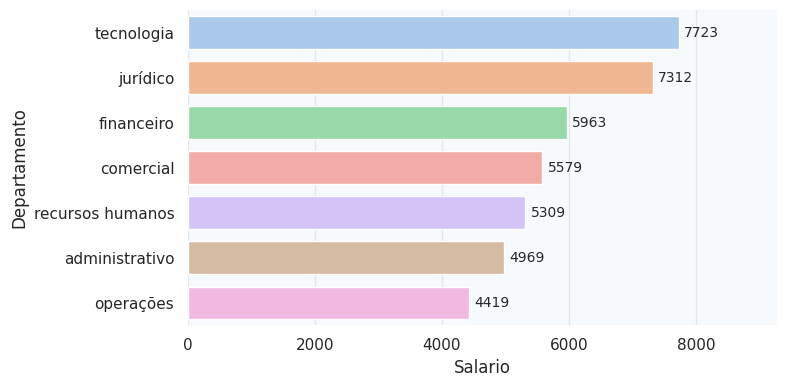

In [7]:
meia_tamanho_departamento = ativos.groupby("departamento").agg(
                        funcionarios=("id", "size"),
                        salario=("salario", "mean")
                    ) \
                    .reset_index() \
                    .sort_values("salario", ascending=False)
print("")
fnc.mostrar(meia_tamanho_departamento)
fnc.barras_horizontal(meia_tamanho_departamento, "departamento", "salario")

### Quais cargos têm maior salário meio?

25
['Baterista', 'Cientista da informação e documentação', 'Optometrista', 'Mensageiro', 'Assistente comercial', 'Analista de RH', 'Técnico de suporte', 'Analista de operações', 'Consultor comercial', 'Advogado', 'Coordenador administrativo', 'Analista financeiro', 'Assistente de RH', 'Desenvolvedor', 'Auxiliar de operações', 'Supervisor de operações', 'Assistente jurídico', 'Gerente comercial', 'Coordenador de tecnologia', 'Assistente administrativo', 'Analista administrativo', 'Assistente financeiro', 'Coordenador financeiro', 'Coordenador jurídico', 'Coordenador de RH']
                                 cargo  funcionarios  salario
             Coordenador de tecnologia            59 14912.95
                  Coordenador jurídico            20 14046.47
                     Gerente comercial            55 11432.44
                Coordenador financeiro            27 10919.57
Cientista da informação e documentação             1  9886.00
                     Coordenador de RH          

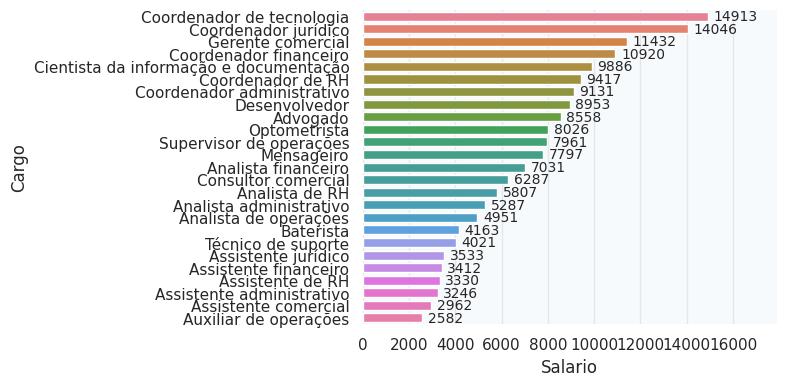

In [8]:
print(len(df["cargo"].unique()))
print(list(df["cargo"].unique()))
df_cargo = df.groupby("cargo").agg(\
        funcionarios=("id", "size"),
        salario=("salario", "mean")
    )\
    .reset_index()\
    .sort_values("salario", ascending=False)

fnc.mostrar(df_cargo, num_show=25)
fnc.barras_horizontal(df_cargo, "cargo", "salario")


    departamento                                  cargo  funcionarios  salario
      tecnologia              Coordenador de tecnologia            59 14912.95
      tecnologia                          Desenvolvedor           190  8952.68
      tecnologia                     Técnico de suporte           160  4021.35
recursos humanos                      Coordenador de RH            31  9416.56
recursos humanos                         Analista de RH           110  5807.40
recursos humanos                       Assistente de RH            85  3329.70
       operações                Supervisor de operações            87  7960.53
       operações                  Analista de operações           262  4951.43
       operações                  Auxiliar de operações           255  2581.51
        jurídico                   Coordenador jurídico            20 14046.47
        jurídico                               Advogado            69  8557.65
        jurídico                    Assistente juríd

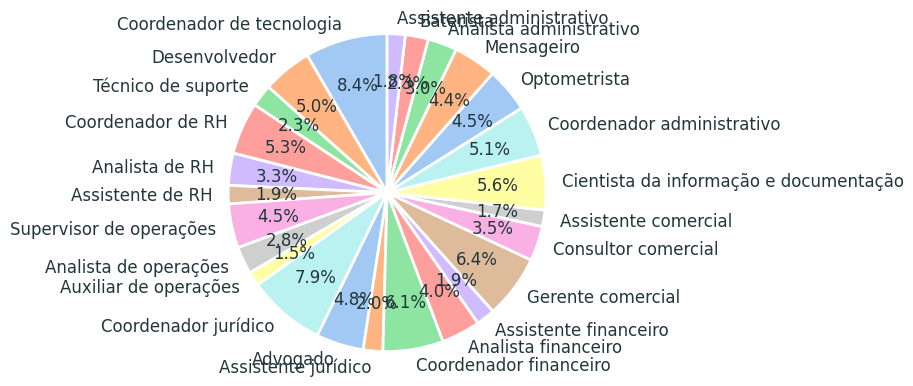

In [9]:
df_cargo = df.groupby(["departamento","cargo"]).agg(\
        funcionarios=("id", "size"),
        salario=("salario", "mean")
    )\
    .reset_index()\
    .sort_values(by=["departamento", "salario"], ascending=False)

fnc.mostrar(df_cargo, num_show=25)

# não usar grafico de pizza com mais de 5 categorias ou muito desvalanceados
fnc.pizza(df_cargo, "cargo", "salario")


### Quais cargos concentram o quadro?

                    cargo    salario
            Desenvolvedor 1701008.47
    Analista de operações 1297274.10
      Consultor comercial 1295075.66
Coordenador de tecnologia  879864.04
      Analista financeiro  857838.10


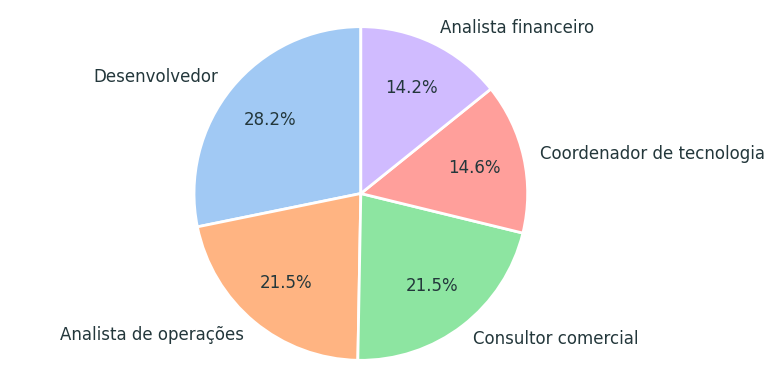

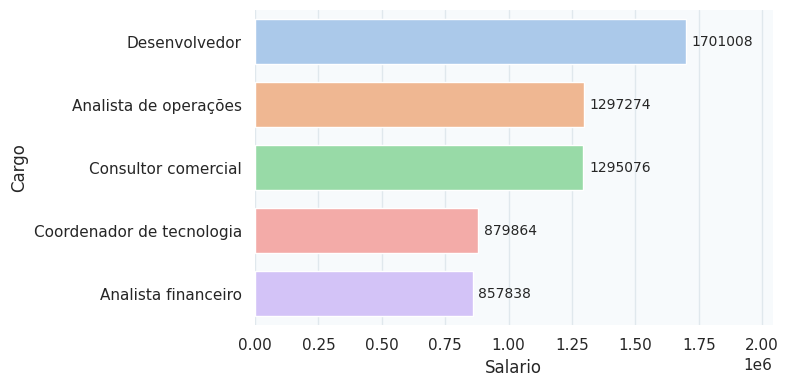

In [10]:
df_cargo_salario = df.groupby("cargo").agg(\
        salario=("salario", "sum")
    )\
    .reset_index()\
    .sort_values("salario", ascending=False).nlargest(5,"salario")

fnc.mostrar(df_cargo_salario)
fnc.pizza(df_cargo_salario, "cargo", "salario")

fnc.barras_horizontal(df_cargo_salario, "cargo", "salario")

### Como se distribui o sexo informado?


     sexo  funcionarios
 Feminino          1189
Masculino          1211


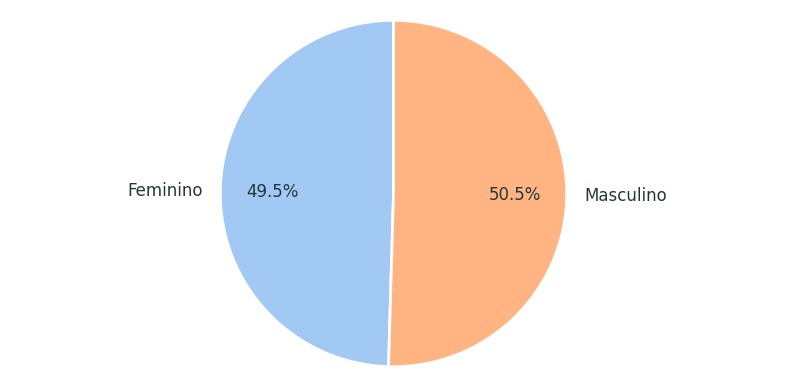

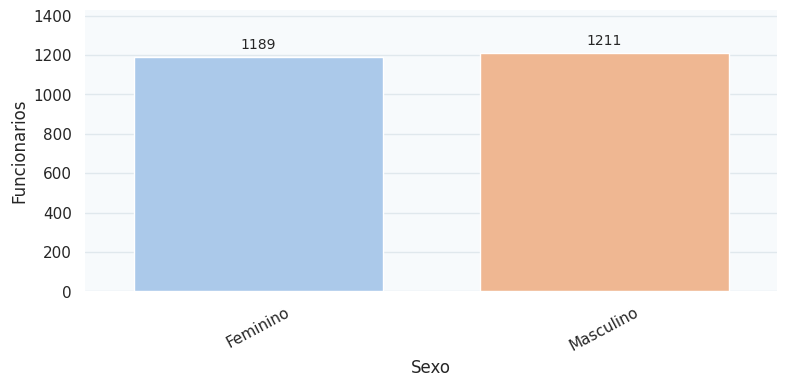

In [11]:
df_sexo = df.groupby("sexo").size().reset_index(name="funcionarios")

fnc.mostrar(df_sexo)

fnc.pizza(df_sexo, "sexo", "funcionarios")

fnc.barras_vertical(df_sexo, "sexo", "funcionarios")

### A composição de sexo por departamentos?


    departamento      sexo  funcionarios
  administrativo  Feminino           120
  administrativo Masculino           121
       comercial  Feminino           188
       comercial Masculino           160
      financeiro  Feminino            91
      financeiro Masculino           102
        jurídico  Feminino            57
        jurídico Masculino            66
       operações  Feminino           218
       operações Masculino           253
recursos humanos  Feminino            88
recursos humanos Masculino            89


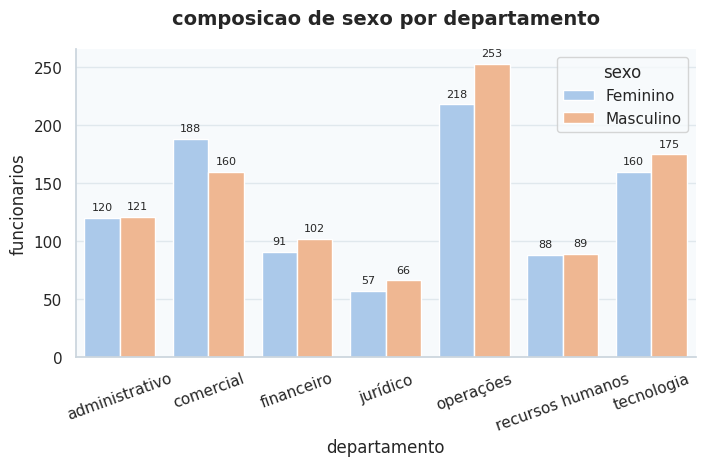

In [12]:
df_sexo_departamento = ativos.groupby(["departamento", "sexo"]).size()\
                        .reset_index(name="funcionarios")
fnc.mostrar(df_sexo_departamento, num_show=12)

# grafico de barra dupla
fig, ax = plt.subplots()
sns.barplot(data=df_sexo_departamento, x="departamento", \
        y="funcionarios", hue="sexo", ax=ax) # hue serve para agrupar e colorir por categoria
ax.set_title("composicao de sexo por departamento")
ax.grid(axis="x", visible=False)
ax.tick_params(axis='x', labelrotation=20)
for grupo in ax.containers:
    ax.bar_label(grupo, fmt="%.0f", padding=4, fontsize=8)
plt.show()

### Qual faixa de idade concentra mais pessoas?

faixa_idade  funcionarios
      20-29           233
      30-39           554
      40-49           655
      50-59           348
      60-69            98


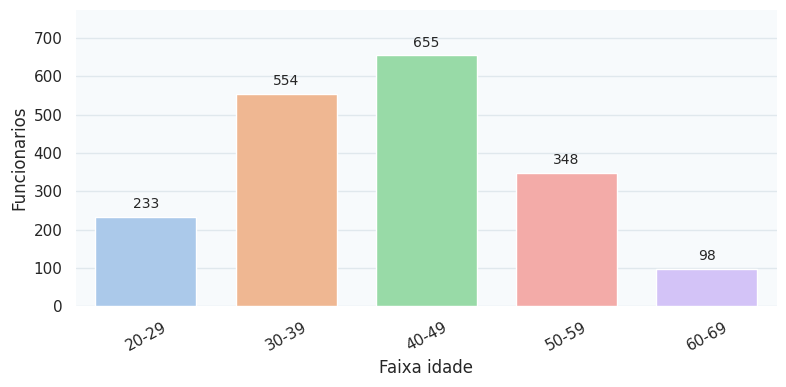

In [13]:
df_faixa_idade = ativos.groupby("faixa_idade").size().reset_index(name="funcionarios")\
                        .sort_values("faixa_idade")

fnc.mostrar(df_faixa_idade)

fnc.barras_vertical(df_faixa_idade, "faixa_idade", "funcionarios")

### Há associação entre idade e salário?

correlacao idade salario 0.28402770452866954 

 id                         nome  salario                                  cargo  idade faixa_idade      sexo data_contratacao status     departamento  ano  mes trimestre  anos_desde_admissao
  0             Anna Liz Sampaio  4163.00                              Baterista     65       60-69 Masculino       2020-01-23  Ativo   administrativo 2020    1    2020Q1                 6.69
  1                   Noah Abreu  9886.00 Cientista da informação e documentação     63       60-69  Feminino       2022-11-29  Ativo   administrativo 2022   11    2022Q4                 3.84
  4       Bruno Ferreira Esteves  2526.17                   Assistente comercial     45       40-49  Feminino       2023-06-15  Ativo        comercial 2023    6    2023Q2                 3.29
  5          Valéria Costa Gomes  4864.94                         Analista de RH     29       20-29 Masculino       2022-10-10  Ativo recursos humanos 2022   10    2022Q4               

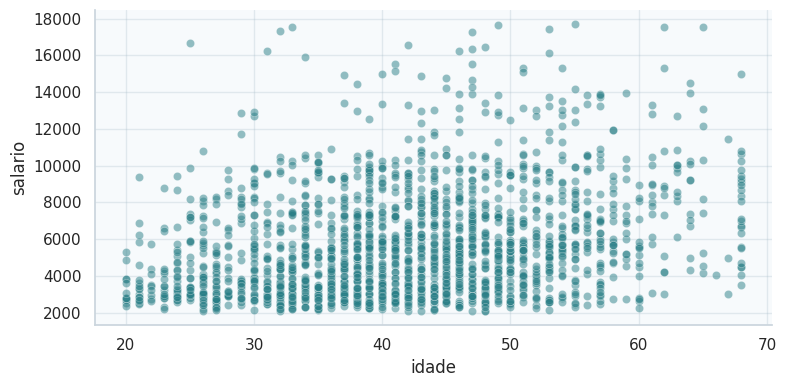

In [15]:
df_idade_salario = ativos.groupby(["idade", "salario"]).head(5)
corr_idade_salario = ativos["idade"].corr(ativos["salario"])
print("correlacao idade salario", corr_idade_salario, "\n")
fnc.mostrar(df_idade_salario)

fnc.dispersao(ativos, "idade", "salario")

### Quantas admissões constam em cada ano?

 id                         nome  salario                                  cargo  idade faixa_idade      sexo data_contratacao status     departamento  ano  mes trimestre  anos_desde_admissao
  1                   Noah Abreu  9886.00 Cientista da informação e documentação     63       60-69  Feminino       2022-11-29  Ativo   administrativo 2022   11    2022Q4                 3.84
  4       Bruno Ferreira Esteves  2526.17                   Assistente comercial     45       40-49  Feminino       2023-06-15  Ativo        comercial 2023    6    2023Q2                 3.29
  5          Valéria Costa Gomes  4864.94                         Analista de RH     29       20-29 Masculino       2022-10-10  Ativo recursos humanos 2022   10    2022Q4                 3.97
  6   Gabriela Vieira Nascimento  4257.53                     Técnico de suporte     30       30-39 Masculino       2024-03-21  Ativo       tecnologia 2024    3    2024Q1                 2.53
  9 Camila Nascimento Nascimento  4827.7

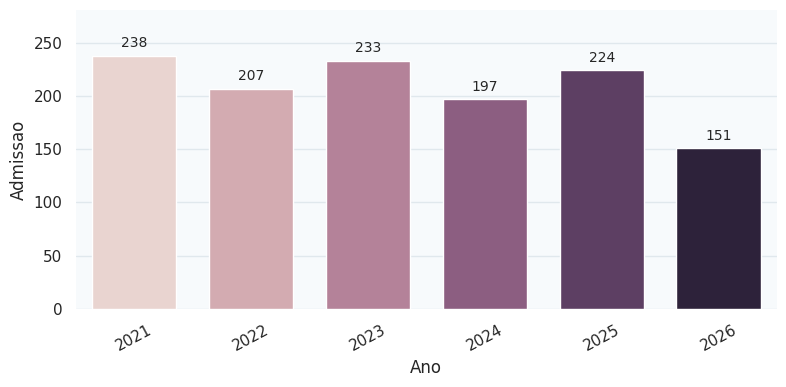

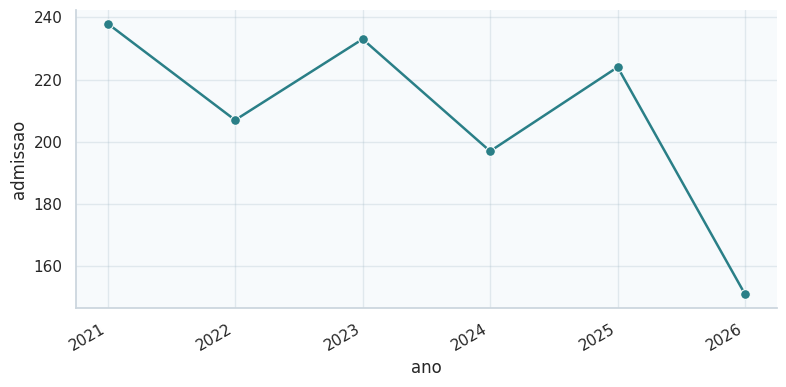

In [31]:
df_ativos_2021 = ativos[ativos["ano"] > 2020]
fnc.mostrar(df_ativos_2021)

df_admissoes_ano = df_ativos_2021.groupby("ano").size().reset_index(name="admissao").sort_values("ano")

fnc.mostrar(df_admissoes_ano, num_show=len(df_ativos_2021["ano"].unique()))

fnc.barras_vertical(df_admissoes_ano, "ano", "admissao")

fnc.linhas(df_admissoes_ano, "ano", "admissao")